<a href="https://colab.research.google.com/github/Khadeeja-beevi12/Module-end-assessment-Entri/blob/main/Statistics_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Statistics Project: Customer Behavior Analysis Using Python

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:
from google.colab import files
import pandas as pd

uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print(df.head())
print("Dataset shape:", df.shape)


Saving customer_behavior.csv to customer_behavior.csv
Dataset loaded successfully!
   CustomerID  Gender Region  PurchaseAmount ProductCategory Churn  \
0        1001    Male  South          256.07         Fashion    No   
1        1002  Female  South             NaN     Electronics   Yes   
2        1003  Female   West         1194.41         Fashion    No   
3        1004  Female  South          413.06         Grocery    No   
4        1005    Male   West         1556.32         Fashion   Yes   

  CampaignGroup  
0             A  
1             B  
2             A  
3             A  
4             A  
Dataset shape: (5000, 7)


In [7]:
df = pd.read_csv("customer_behavior.csv")

**Question 1**. What is the average, median, and mode of PurchaseAmount?

In [9]:
purchase = df["PurchaseAmount"].dropna()

print("Average:", round(purchase.mean(), 2))
print("Median:", round(purchase.median(), 2))
print("Mode:", purchase.mode().tolist())


Average: 1003.95
Median: 998.08
Mode: [0.0]


**Question 2**. Are there any outliers in the PurchaseAmount data?

Lower limit: -306.51
Upper limit: 2307.23
Number of outliers: 15
Outlier values:
[2318.33, 2496.41, 2688.69, 2349.16, 2578.89, 2384.19, 2457.05, 2316.19, 2400.69, 2357.41, 2688.88, 2643.88, 2472.62, 2484.75, 2642.06]


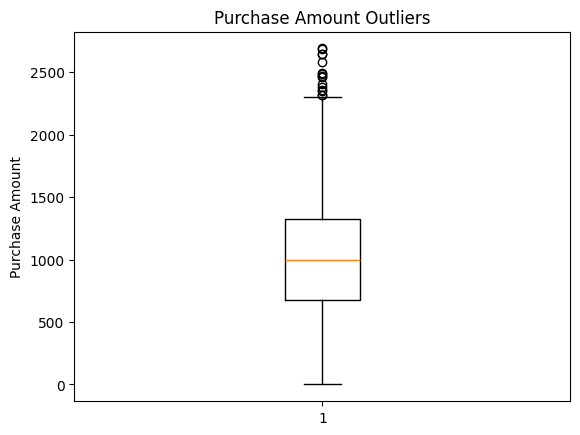

In [10]:
purchase = df["PurchaseAmount"].dropna()

Q1 = purchase.quantile(0.25)
Q3 = purchase.quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = purchase[
    (purchase < lower) | (purchase > upper)
]

print("Lower limit:", round(lower, 2))
print("Upper limit:", round(upper, 2))
print("Number of outliers:", len(outliers))
print("Outlier values:")
print(outliers.tolist())

plt.boxplot(purchase)
plt.title("Purchase Amount Outliers")
plt.ylabel("Purchase Amount")
plt.show()


**Question 3**. Is there any skewness or kurtosis in the PurchaseAmount distribution?

Skewness: 0.106
Excess Kurtosis: -0.262
The distribution is positively skewed.
The distribution has negative excess kurtosis.


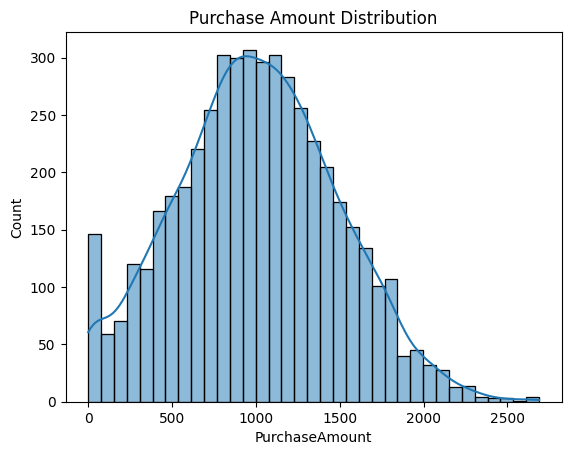

In [11]:
purchase = df["PurchaseAmount"].dropna()

skewness = purchase.skew()
kurtosis = purchase.kurt()

print("Skewness:", round(skewness, 3))
print("Excess Kurtosis:", round(kurtosis, 3))

if skewness > 0:
    print("The distribution is positively skewed.")
elif skewness < 0:
    print("The distribution is negatively skewed.")
else:
    print("The distribution is approximately symmetric.")

if kurtosis > 0:
    print("The distribution has positive excess kurtosis.")
elif kurtosis < 0:
    print("The distribution has negative excess kurtosis.")
else:
    print("The excess kurtosis is approximately zero.")

sns.histplot(purchase, kde=True)
plt.title("Purchase Amount Distribution")
plt.show()


**Question 4**. Is there a significant difference in spending between male and female customers?

In [12]:
gender_data = df.dropna(
    subset=["Gender", "PurchaseAmount"]
).copy()

gender_data["Gender"] = gender_data["Gender"].str.strip()

male = gender_data.loc[
    gender_data["Gender"] == "Male", "PurchaseAmount"
]

female = gender_data.loc[
    gender_data["Gender"] == "Female", "PurchaseAmount"
]

print("Male average spending:", round(male.mean(), 2))
print("Female average spending:", round(female.mean(), 2))

t_stat, p_value = stats.ttest_ind(
    male, female, equal_var=False
)

print("T-statistic:", round(t_stat, 3))
print("P-value:", round(p_value, 4))

if p_value < 0.05:
    print("There is a significant difference in spending.")
else:
    print("There is no significant difference in spending.")


Male average spending: 1019.18
Female average spending: 987.87
T-statistic: 2.235
P-value: 0.0255
There is a significant difference in spending.


**Question 5**. Is there a relationship between ProductCategory and customer churn?

In [13]:
category_data = df.dropna(
    subset=["ProductCategory", "Churn"]
).copy()

category_data["ProductCategory"] = (
    category_data["ProductCategory"].str.strip()
)
category_data["Churn"] = category_data["Churn"].str.strip()

table = pd.crosstab(
    category_data["ProductCategory"],
    category_data["Churn"]
)

print("Contingency table:")
print(table)

chi2, p_value, dof, expected = stats.chi2_contingency(table)

print("Chi-square statistic:", round(chi2, 3))
print("P-value:", round(p_value, 4))

if p_value < 0.05:
    print("Product category and churn are significantly associated.")
else:
    print("No significant association was found.")

print("\nChurn percentage by product category:")
print(
    pd.crosstab(
        category_data["ProductCategory"],
        category_data["Churn"],
        normalize="index"
    ).mul(100).round(2)
)


Contingency table:
Churn             No  Yes
ProductCategory          
Electronics      785  541
Fashion          839  607
Grocery          855  604
Chi-square statistic: 0.396
P-value: 0.8204
No significant association was found.

Churn percentage by product category:
Churn               No    Yes
ProductCategory              
Electronics      59.20  40.80
Fashion          58.02  41.98
Grocery          58.60  41.40


A p-value below 0.05 indicates a significant association between product category and churn. This does not establish that the product category causes churn.

**Question 6**. Does PurchaseAmount vary significantly across different regions?

In [14]:
region_data = df.dropna(
    subset=["Region", "PurchaseAmount"]
).copy()

region_data["Region"] = region_data["Region"].str.strip()

print("Average purchase amount by region:")
print(
    region_data.groupby("Region")["PurchaseAmount"].mean().round(2)
)

groups = [
    group["PurchaseAmount"].values
    for _, group in region_data.groupby("Region")
]

f_stat, p_value = stats.f_oneway(*groups)

print("F-statistic:", round(f_stat, 3))
print("P-value:", round(p_value, 4))

if p_value < 0.05:
    print("Spending differs significantly across regions.")
else:
    print("No significant difference across regions was found.")


Average purchase amount by region:
Region
East     1009.95
North    1013.02
South     997.60
West      995.25
Name: PurchaseAmount, dtype: float64
F-statistic: 0.39
P-value: 0.7605
No significant difference across regions was found.


**Question 7**. Which email campaign (A or B) performed better in terms of average PurchaseAmount?

In [15]:

campaign_data = df.dropna(
    subset=["CampaignGroup", "PurchaseAmount"]
).copy()

campaign_data["CampaignGroup"] = (
    campaign_data["CampaignGroup"].str.strip()
)

campaign_means = campaign_data.groupby(
    "CampaignGroup"
)["PurchaseAmount"].mean()

print("Average spending by campaign:")
print(campaign_means.round(2))

if "A" in campaign_means.index and "B" in campaign_means.index:
    if campaign_means["A"] > campaign_means["B"]:
        print("Campaign A performed better in average spending.")
    elif campaign_means["B"] > campaign_means["A"]:
        print("Campaign B performed better in average spending.")
    else:
        print("Both campaigns have equal average spending.")
else:
    print("Campaign A or B data is missing.")


Average spending by campaign:
CampaignGroup
A    1011.95
B     994.34
Name: PurchaseAmount, dtype: float64
Campaign A performed better in average spending.


**Question 8**. Can we assume PurchaseAmount follows a normal distribution?

Shapiro-Wilk statistic: 0.995
P-value: 0.0
Reject normality: the data is not consistent with a normal distribution.


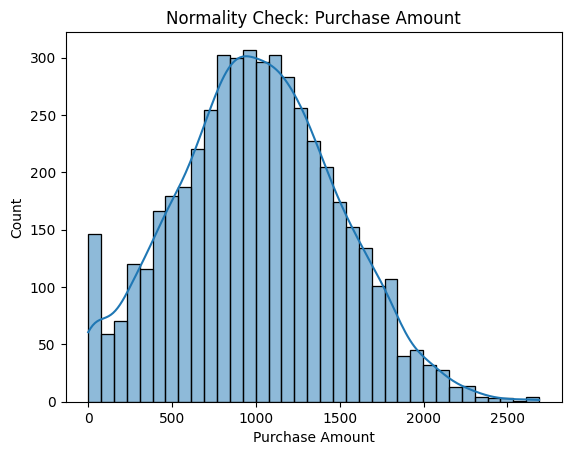

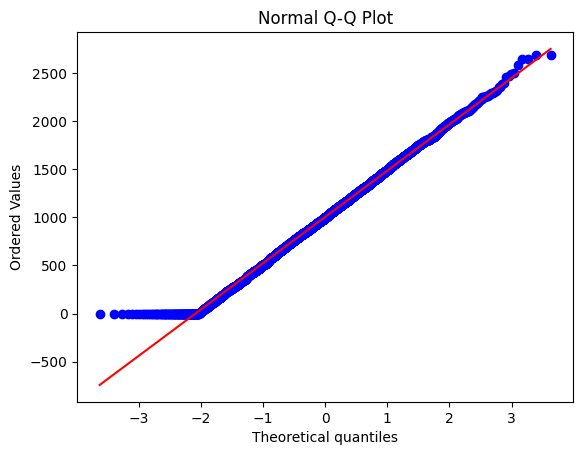

In [16]:
purchase = df["PurchaseAmount"].dropna()

# Shapiro-Wilk test on a sample of up to 5,000 values
sample = purchase.sample(
    n=min(5000, len(purchase)),
    random_state=42
)

statistic, p_value = stats.shapiro(sample)

print("Shapiro-Wilk statistic:", round(statistic, 4))
print("P-value:", round(p_value, 4))

if p_value < 0.05:
    print("Reject normality: the data is not consistent with a normal distribution.")
else:
    print("Do not reject normality: there is insufficient evidence against normality.")

sns.histplot(purchase, kde=True)
plt.title("Normality Check: Purchase Amount")
plt.xlabel("Purchase Amount")
plt.show()

stats.probplot(purchase, dist="norm", plot=plt)
plt.title("Normal Q-Q Plot")
plt.show()


A p-value below 0.05 suggests that PurchaseAmount is not normally distributed. A p-value at or above 0.05 does not prove normality; the histogram and Q-Q plot should also be examined.

**Question 9**. What insights can we gain by applying the Central Limit Theorem?

Original mean: 1003.95
Mean of sample means: 1000.96
Standard deviation of sample means: 89.98
Theoretical standard error: 88.02


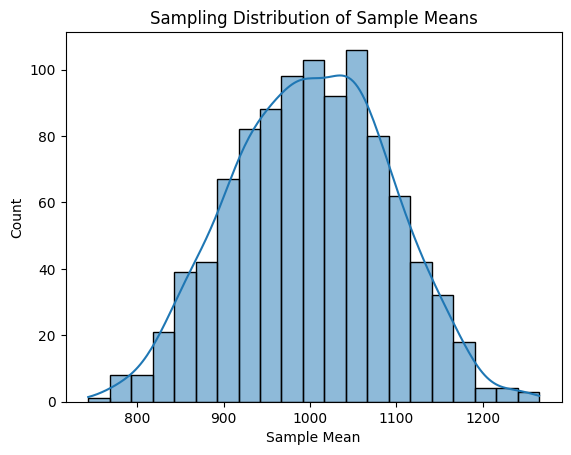

In [17]:
purchase = df["PurchaseAmount"].dropna()

sample_size = 30
number_of_samples = 1000

sample_means = []

for i in range(number_of_samples):
    sample = purchase.sample(
        n=sample_size,
        replace=True,
        random_state=i
    )
    sample_means.append(sample.mean())

print("Original mean:", round(purchase.mean(), 2))
print("Mean of sample means:", round(np.mean(sample_means), 2))
print("Standard deviation of sample means:",
      round(np.std(sample_means, ddof=1), 2))
print("Theoretical standard error:",
      round(purchase.std(ddof=1) / np.sqrt(sample_size), 2))

sns.histplot(sample_means, kde=True)
plt.title("Sampling Distribution of Sample Means")
plt.xlabel("Sample Mean")
plt.show()


The Central Limit Theorem (CLT) says that the distribution of sample means tends toward a normal distribution as the sample size increases, under suitable conditions.
The sample means should cluster around the overall mean. Their distribution tends to become more bell-shaped with sufficiently large samples, and their variability is smaller than that of individual purchase amounts.

**Question 10**. What is the 95% confidence interval for the average PurchaseAmount?

In [18]:
purchase = df["PurchaseAmount"].dropna()

n = len(purchase)
mean = purchase.mean()
standard_error = stats.sem(purchase)

lower, upper = stats.t.interval(
    confidence=0.95,
    df=n - 1,
    loc=mean,
    scale=standard_error
)

print("Sample size:", n)
print("Average PurchaseAmount:", round(mean, 2))
print("Standard error:", round(standard_error, 2))
print("95% Confidence Interval:")
print("Lower limit:", round(lower, 2))
print("Upper limit:", round(upper, 2))
print(
    f"We are 95% confident that the population mean lies between "
    f"{lower:.2f} and {upper:.2f}."
)


Sample size: 4850
Average PurchaseAmount: 1003.95
Standard error: 6.92
95% Confidence Interval:
Lower limit: 990.38
Upper limit: 1017.52
We are 95% confident that the population mean lies between 990.38 and 1017.52.


The output gives the lower and upper limits of the 95% confidence interval. It describes uncertainty about the population mean, rather than the range containing 95% of individual customers' purchase amounts.